In [1]:
%pip install qiskit qiskit-aer scipy networkx matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.8/9.8 MB 24.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 57.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 71.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.9/54.9 kB 3.0 MB/s eta 0:00:00


In [2]:
import qiskit
import scipy
import networkx as nx
import matplotlib.pyplot as plt

print("Qiskit version:", qiskit.__version__)
print("SciPy version:", scipy.__version__)
print("NetworkX version:", nx.__version__)
print("Environment check completed!")


Qiskit version: 2.5.2
SciPy version: 1.16.3
NetworkX version: 3.7
Environment check completed!


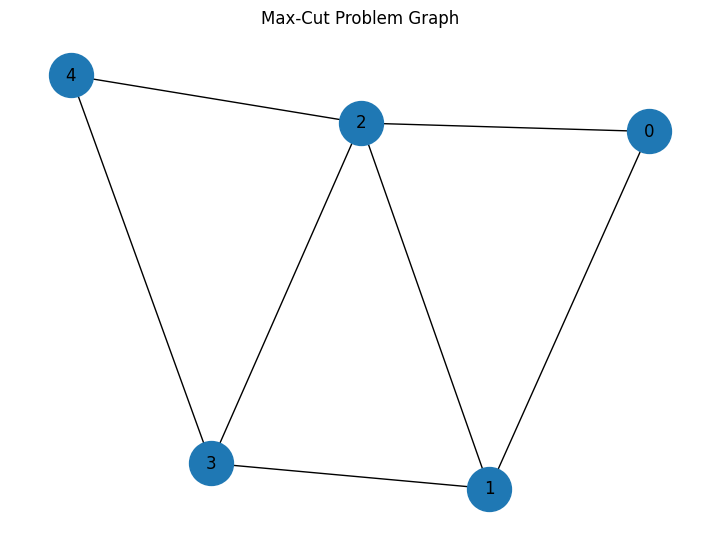

Number of vertices: 5
Number of edges: 7


In [3]:
import networkx as nx
import matplotlib.pyplot as plt

# Small example graph for the Max-Cut problem
G = nx.Graph()
G.add_weighted_edges_from([
    (0, 1, 1),
    (0, 2, 1),
    (1, 2, 1),
    (1, 3, 1),
    (2, 3, 1),
    (2, 4, 1),
    (3, 4, 1)
])

pos = nx.spring_layout(G, seed=42)

plt.figure(figsize=(7, 5))
nx.draw(
    G, pos,
    with_labels=True,
    node_size=1000,
    font_size=12
)
plt.title("Max-Cut Problem Graph")
plt.show()

print("Number of vertices:", G.number_of_nodes())
print("Number of edges:", G.number_of_edges())

In [4]:
from itertools import product

def cut_value(graph, partition):
    total = 0

    for u, v, data in graph.edges(data=True):
        if partition[u] != partition[v]:
            total += data.get("weight", 1)

    return total

best_value = -1
best_partition = None

vertices = list(G.nodes())

# Fix the first vertex in group 0 to avoid checking
# both a partition and its equivalent swapped partition.
for remaining in product([0, 1], repeat=len(vertices) - 1):
    partition = (0,) + remaining
    value = cut_value(G, dict(zip(vertices, partition)))

    if value > best_value:
        best_value = value
        best_partition = partition

print("Classical best cut value:", best_value)
print("Partition:", best_partition)

Classical best cut value: 5
Partition: (0, 0, 1, 1, 0)


In [5]:
print("PROJECT: Quantum Max-Cut")
print("CLASSICAL BASELINE")
print("------------------")
print("Vertices:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Best cut value:", best_value)
print("Best partition:", best_partition)
print("Status: Classical baseline completed")

PROJECT: Quantum Max-Cut
CLASSICAL BASELINE
------------------
Vertices: 5
Edges: 7
Best cut value: 5
Best partition: (0, 0, 1, 1, 0)
Status: Classical baseline completed


In [6]:
# QAOA preparation: inspect the graph and available Qiskit components

from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from scipy.optimize import minimize
import networkx as nx
import matplotlib.pyplot as plt

print("Graph vertices:", G.number_of_nodes())
print("Graph edges:", G.number_of_edges())
print("Classical best cut:", best_value)
print("Qiskit and optimization components imported successfully.")

Graph vertices: 5
Graph edges: 7
Classical best cut: 5
Qiskit and optimization components imported successfully.


In [7]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator

qc = QuantumCircuit(G.number_of_nodes())
print("Number of qubits:", qc.num_qubits)
print("Circuit initialized successfully.")

Number of qubits: 5
Circuit initialized successfully.


In [8]:
from qiskit import QuantumCircuit
import numpy as np

n = G.number_of_nodes()

# Initialize the quantum state
qc = QuantumCircuit(n)

# Create an equal superposition of all bitstrings
for qubit in range(n):
    qc.h(qubit)

print(qc.draw(output="text"))

     ┌───┐
q_0: ┤ H ├
     ├───┤
q_1: ┤ H ├
     ├───┤
q_2: ┤ H ├
     ├───┤
q_3: ┤ H ├
     ├───┤
q_4: ┤ H ├
     └───┘


## QAOA Cost and Mixer Layers
### Cost Layer The cost layer encodes the Max-Cut objective using interactions between qubits connected by graph edges. The parameter gamma (γ) controls this layer.
### Mixer Layer The mixer layer applies parameterized single-qubit rotations. The parameter beta (β) controls the mixer.

### Optimization A classical optimizer searches for parameter values that improve the expected cut value obtained from quantum measurements.

In [10]:
print("Edges in the Max-Cut graph:")
for u, v, data in G.edges(data=True):
    print(f"{u} -- {v}, weight = {data.get('weight', 1)}")

Edges in the Max-Cut graph:
0 -- 1, weight = 1
0 -- 2, weight = 1
1 -- 2, weight = 1
1 -- 3, weight = 1
2 -- 3, weight = 1
2 -- 4, weight = 1
3 -- 4, weight = 1


In [11]:
assert G.number_of_nodes() == 5
assert G.number_of_edges() == 7
assert best_value == 5

print("Graph verification: PASS")
print("Vertices:", G.number_of_nodes())
print("Edges:", G.number_of_edges())
print("Classical best cut:", best_value)
print("Ready to continue QAOA development.")

Graph verification: PASS
Vertices: 5
Edges: 7
Classical best cut: 5
Ready to continue QAOA development.


In [12]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
import numpy as np

n = G.number_of_nodes()

# Check simulator availability
simulator = AerSimulator()

print("Number of qubits:", n)
print("Simulator:", type(simulator).__name__)
print("Classical benchmark:", best_value)
print("QAOA experiment setup: PASS")

Number of qubits: 5
Simulator: AerSimulator
Classical benchmark: 5
QAOA experiment setup: PASS


## QAOA Cost Layer

The cost layer encodes the Max-Cut objective.

For each graph edge (u, v), the circuit applies a two-qubit interaction controlled by the parameter gamma (γ).

The cost Hamiltonian is:

C = Σ w(u,v) [1 - Z(u)Z(v)] / 2

where:
- E represents the graph edges.
- w(u,v) is the edge weight.
- Z represents the Pauli-Z operator.
- γ controls the cost-layer evolution.

In [13]:
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter

n = G.number_of_nodes()
gamma = Parameter("gamma")
beta = Parameter("beta")

qc = QuantumCircuit(n)

# Initial superposition
for q in range(n):
    qc.h(q)

print("Parameterized QAOA circuit initialized.")
print("Qubits:", qc.num_qubits)
print("Parameters:", gamma, beta)
print(qc.draw(output="text"))

Parameterized QAOA circuit initialized.
Qubits: 5
Parameters: gamma beta
     ┌───┐
q_0: ┤ H ├
     ├───┤
q_1: ┤ H ├
     ├───┤
q_2: ┤ H ├
     ├───┤
q_3: ┤ H ├
     ├───┤
q_4: ┤ H ├
     └───┘


In [14]:
# QAOA Cost Layer — Max-Cut

from qiskit import QuantumCircuit
from qiskit.circuit import Parameter

n = G.number_of_nodes()
gamma = Parameter("gamma")
beta = Parameter("beta")

qc = QuantumCircuit(n)

# Step 1: Initial superposition
for q in range(n):
    qc.h(q)

# Step 2: Cost layer — one interaction for each graph edge
for u, v, data in G.edges(data=True):
    weight = data.get("weight", 1)
    qc.rzz(gamma * weight, u, v)

print("QAOA cost layer initialized successfully!")
print("Number of qubits:", qc.num_qubits)
print("Number of graph edges:", G.number_of_edges())
print("Circuit parameters:", qc.parameters)
print(qc.draw(output="text"))

QAOA cost layer initialized successfully!
Number of qubits: 5
Number of graph edges: 7
Circuit parameters: ParameterView([Parameter(gamma)])
     ┌───┐                                                            »
q_0: ┤ H ├─■───────────■──────────────────────────────────────────────»
     ├───┤ │ZZ(gamma)  │                                              »
q_1: ┤ H ├─■───────────┼───────────■───────────■──────────────────────»
     ├───┤             │ZZ(gamma)  │ZZ(gamma)  │                      »
q_2: ┤ H ├─────────────■───────────■───────────┼───────────■──────────»
     ├───┤                                     │ZZ(gamma)  │ZZ(gamma) »
q_3: ┤ H ├─────────────────────────────────────■───────────■──────────»
     ├───┤                                                            »
q_4: ┤ H ├────────────────────────────────────────────────────────────»
     └───┘                                                            »
«                             
«q_0: ────────────────────────
«    

In [15]:
# QAOA Mixer Layer

# Apply the mixer rotation to every qubit
for q in range(n):
    qc.rx(2 * beta, q)

print("QAOA mixer layer added successfully!")
print("Circuit parameters:", qc.parameters)
print(qc.draw(output="text"))

QAOA mixer layer added successfully!
Circuit parameters: ParameterView([Parameter(beta), Parameter(gamma)])
     ┌───┐                        ┌────────────┐                          »
q_0: ┤ H ├─■───────────■──────────┤ Rx(2*beta) ├──────────────────────────»
     ├───┤ │ZZ(gamma)  │          └────────────┘            ┌────────────┐»
q_1: ┤ H ├─■───────────┼────────────■────────────■──────────┤ Rx(2*beta) ├»
     ├───┤             │ZZ(gamma)   │ZZ(gamma)   │          └────────────┘»
q_2: ┤ H ├─────────────■────────────■────────────┼────────────■───────────»
     ├───┤                                       │ZZ(gamma)   │ZZ(gamma)  »
q_3: ┤ H ├───────────────────────────────────────■────────────■───────────»
     ├───┤                                                                »
q_4: ┤ H ├────────────────────────────────────────────────────────────────»
     └───┘                                                                »
«                                             
«q_0: ───

In [17]:
# STEP 10: Validate the QAOA circuit

print("Qubits:", qc.num_qubits)
print("Graph edges:", G.number_of_edges())
print("Parameters:", sorted([p.name for p in qc.parameters]))
print("Circuit depth:", qc.depth())
print("Circuit operations:", qc.count_ops())

assert qc.num_qubits == 5
assert G.number_of_edges() == 7
assert {p.name for p in qc.parameters} == {"gamma", "beta"}

print("\nCircuit validation: PASSED")

Qubits: 5
Graph edges: 7
Parameters: ['beta', 'gamma']
Circuit depth: 9
Circuit operations: OrderedDict({'rzz': 7, 'h': 5, 'rx': 5})

Circuit validation: PASSED


In [18]:
# STEP 11: Add measurement to the QAOA circuit

qc_measured = qc.copy()
qc_measured.measure_all()

print("Measurement added successfully!")
print("Measured circuit depth:", qc_measured.depth())
print(qc_measured.draw(output="text"))

Measurement added successfully!
Measured circuit depth: 10
        ┌───┐                        ┌────────────┐                          »
   q_0: ┤ H ├─■───────────■──────────┤ Rx(2*beta) ├──────────────────────────»
        ├───┤ │ZZ(gamma)  │          └────────────┘            ┌────────────┐»
   q_1: ┤ H ├─■───────────┼────────────■────────────■──────────┤ Rx(2*beta) ├»
        ├───┤             │ZZ(gamma)   │ZZ(gamma)   │          └────────────┘»
   q_2: ┤ H ├─────────────■────────────■────────────┼────────────■───────────»
        ├───┤                                       │ZZ(gamma)   │ZZ(gamma)  »
   q_3: ┤ H ├───────────────────────────────────────■────────────■───────────»
        ├───┤                                                                »
   q_4: ┤ H ├────────────────────────────────────────────────────────────────»
        └───┘                                                                »
meas: 5/════════════════════════════════════════════════════════════════

In [19]:
# STEP 12: Test the measured QAOA circuit

from qiskit_aer import AerSimulator

simulator = AerSimulator()
print("Simulator initialized:", simulator.name)
print("Shots:", 1024)

# Use temporary test parameters
test_parameters = {gamma: 0.5, beta: 0.25}
bound_circuit = qc_measured.assign_parameters(test_parameters)

job = simulator.run(bound_circuit, shots=1024)
result = job.result()
counts = result.get_counts()

print("\nMeasurement results:")
print(counts)

print("\nTotal shots:", sum(counts.values()))

Simulator initialized: aer_simulator
Shots: 1024

Measurement results:
{'10011': 3, '10110': 5, '01010': 24, '11110': 61, '01111': 71, '00110': 8, '00001': 51, '11100': 34, '10100': 27, '10111': 26, '10101': 30, '10010': 8, '11000': 38, '00010': 38, '10000': 50, '11111': 128, '11011': 14, '11010': 16, '10001': 17, '00101': 15, '01001': 4, '00000': 146, '11001': 12, '00011': 43, '00111': 45, '01101': 4, '11101': 35, '01110': 18, '00100': 9, '01000': 19, '01100': 6, '01011': 19}

Total shots: 1024


In [20]:
# STEP 13: Evaluate measured bitstrings

def evaluate_bitstring(bitstring, graph):
    # Qiskit displays classical bits in reverse order
    partition = [int(bit) for bit in bitstring[::-1]]

    cut = 0
    for u, v, data in graph.edges(data=True):
        if partition[u] != partition[v]:
            cut += data.get("weight", 1)

    return cut

# Calculate the cut value for every measured outcome
cut_results = {}

for bitstring, frequency in counts.items():
    cut = evaluate_bitstring(bitstring, G)
    cut_results[bitstring] = {
        "cut_value": cut,
        "frequency": frequency
    }

# Most frequently measured outcome
most_common = max(counts, key=counts.get)

# Best outcome observed
best_bitstring = max(
    cut_results,
    key=lambda bitstring: cut_results[bitstring]["cut_value"]
)

print("Classical best cut:", best_value)
print("Most frequent bitstring:", most_common)
print("Its cut value:", cut_results[most_common]["cut_value"])
print("Best measured bitstring:", best_bitstring)
print("Best measured cut:", cut_results[best_bitstring]["cut_value"])
print("QAOA test parameters: gamma=0.5, beta=0.25")

Classical best cut: 5
Most frequent bitstring: 00000
Its cut value: 0
Best measured bitstring: 10011
Best measured cut: 5
QAOA test parameters: gamma=0.5, beta=0.25


In [21]:
# STEP 14: Measurement statistics

total_shots = sum(counts.values())

cut_frequency = sum(
    frequency
    for bitstring, frequency in counts.items()
    if evaluate_bitstring(bitstring, G) == best_value
)

average_cut = sum(
    evaluate_bitstring(bitstring, G) * frequency
    for bitstring, frequency in counts.items()
) / total_shots

print("Total shots:", total_shots)
print("Classical optimal cut:", best_value)
print("Shots achieving the optimal cut:", cut_frequency)
print("Optimal-cut probability:", round(cut_frequency / total_shots, 4))
print("Average measured cut:", round(average_cut, 4))

Total shots: 1024
Classical optimal cut: 5
Shots achieving the optimal cut: 50
Optimal-cut probability: 0.0488
Average measured cut: 2.252


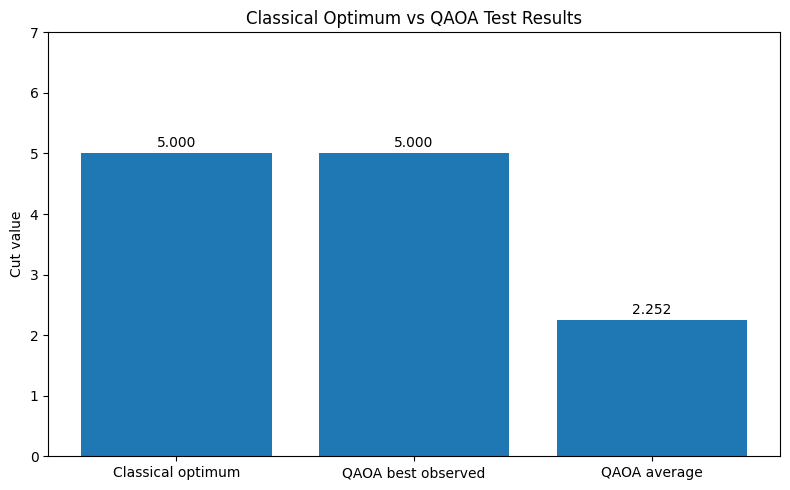

Chart saved as qaoa_results.png


In [22]:
# STEP 15: Visualize QAOA test results

import matplotlib.pyplot as plt

labels = ["Classical optimum", "QAOA best observed", "QAOA average"]
values = [best_value, cut_results[best_bitstring]["cut_value"], average_cut]

plt.figure(figsize=(8, 5))
bars = plt.bar(labels, values)
plt.ylabel("Cut value")
plt.title("Classical Optimum vs QAOA Test Results")
plt.ylim(0, 7)

for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.1,
        f"{value:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.savefig("qaoa_results.png", dpi=300)
plt.show()

print("Chart saved as qaoa_results.png")

In [23]:
# STEP 16: Compare different QAOA parameter settings

from qiskit_aer import AerSimulator

simulator = AerSimulator()
parameter_sets = [
    (0.5, 0.25),
    (1.0, 0.5),
    (1.5, 0.75),
    (2.0, 1.0)
]

print("QAOA Parameter Experiment")
print("-" * 60)

for gamma_value, beta_value in parameter_sets:
    bound_circuit = qc_measured.assign_parameters({
        gamma: gamma_value,
        beta: beta_value
    })

    result = simulator.run(
        bound_circuit,
        shots=1024,
        seed_simulator=42
    ).result()

    trial_counts = result.get_counts()

    average_cut_trial = sum(
        evaluate_bitstring(bitstring, G) * frequency
        for bitstring, frequency in trial_counts.items()
    ) / sum(trial_counts.values())

    best_cut_trial = max(
        evaluate_bitstring(bitstring, G)
        for bitstring in trial_counts
    )

    print(
        f"gamma={gamma_value:.2f}, beta={beta_value:.2f} | "
        f"Average cut={average_cut_trial:.3f} | "
        f"Best cut={best_cut_trial}"
    )

QAOA Parameter Experiment
------------------------------------------------------------
gamma=0.50, beta=0.25 | Average cut=2.312 | Best cut=5
gamma=1.00, beta=0.50 | Average cut=2.045 | Best cut=5
gamma=1.50, beta=0.75 | Average cut=3.530 | Best cut=5
gamma=2.00, beta=1.00 | Average cut=3.643 | Best cut=5


In [24]:
import pandas as pd

results_df = pd.DataFrame({
    "Gamma": [0.5, 1.0, 1.5, 2.0],
    "Beta": [0.25, 0.5, 0.75, 1.0],
    "Average_Cut": [2.312, 2.045, 3.530, 3.643],
    "Best_Observed_Cut": [5, 5, 5, 5]
})

results_df.to_csv("qaoa_parameter_results.csv", index=False)

print(results_df.to_string(index=False))
print("\nSaved: qaoa_parameter_results.csv")

 Gamma  Beta  Average_Cut  Best_Observed_Cut
   0.5  0.25        2.312                  5
   1.0  0.50        2.045                  5
   1.5  0.75        3.530                  5
   2.0  1.00        3.643                  5

Saved: qaoa_parameter_results.csv


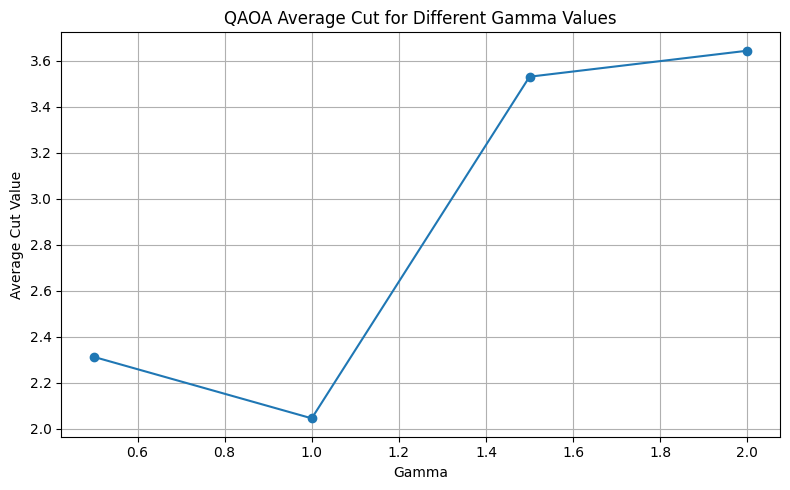

Saved: qaoa_parameter_sweep.png


In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(results_df["Gamma"], results_df["Average_Cut"], marker="o")

plt.xlabel("Gamma")
plt.ylabel("Average Cut Value")
plt.title("QAOA Average Cut for Different Gamma Values")
plt.grid(True)
plt.tight_layout()

plt.savefig("qaoa_parameter_sweep.png", dpi=300)
plt.show()

print("Saved: qaoa_parameter_sweep.png")

In [26]:
from google.colab import files
files.download("qaoa_parameter_sweep.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [27]:
files.download("qaoa_parameter_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>